In [ ]:
## En caso de que decidas trabajar localmente, se recomienda crear un ambiente
## e instalar las librerías. Además deberás cargar localmente las imágenes.
!pip install pandas
!pip install matplotlib
!pip install opencv-python
!pip install mediapipe
!pip install scikit-activeml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 8.6 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.4/255.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 80.4 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.4.4 which is incompatible.


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import kagglehub
import sklearn

# Generar Dataset

Este codigo genera el dataset con los landmarks automáticamente. No modificar.

In [ ]:
import urllib.request
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from sklearn.model_selection import train_test_split

# 1. Descarga del dataset y del modelo
path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Path to dataset files:", path)

MODEL_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"
MODEL_PATH = "hand_landmarker.task"

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

# 2. Configuración de MediaPipe
base_options = mp_python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.HandLandmarkerOptions(base_options=base_options, num_hands=1)
hand_landmarker = vision.HandLandmarker.create_from_options(options)

# 3. Funciones de extracción
def extract_landmarks(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
    results = hand_landmarker.detect(mp_image)

    if results.hand_landmarks:
        all_hand_landmarks = results.hand_landmarks
        coords = []
        for hand_landmarks_list in all_hand_landmarks:
            for lm in hand_landmarks_list:
                coords.extend([lm.x, lm.y, lm.z])
        return coords
    return None

def process_dataset(base_dir, letters=None, max_per_class=1000):
    if letters is None:
        letters = []

    data = []
    total_por_categoria = {}
    detectadas_por_categoria = {}

    for label in letters:
        label_dir = os.path.join(base_dir, label)
        if not os.path.isdir(label_dir):
            continue

        total_por_categoria[label] = 0
        detectadas_por_categoria[label] = 0

        all_images = os.listdir(label_dir)
        rng = np.random.default_rng(42)
        selected_images = rng.choice(
            all_images,
            size=min(max_per_class, len(all_images)),
            replace=False
        )

        for img_file in tqdm(selected_images, desc=f"Procesando {label}"):
            total_por_categoria[label] += 1
            img_path = os.path.join(label_dir, img_file)

            features = extract_landmarks(img_path)

            if features:
                detectadas_por_categoria[label] += 1
                data.append(features + [label, img_file])

    return data, total_por_categoria, detectadas_por_categoria

# 4. Ejecución de la extracción
train_dir = os.path.join(path, "asl_alphabet_train/asl_alphabet_train")
letters = ["A", "B", "C", "D", "E"]

print("Procesando TRAIN...")
train_data, total_por_categoria, detectadas_por_categoria = process_dataset(train_dir, letters, max_per_class=1000)

print("\nResumen de detecciones por categoria:")
for label in letters:
    total = total_por_categoria.get(label, 0)
    detectadas = detectadas_por_categoria.get(label, 0)
    print(f"{label}: {detectadas}/{total} detectadas")

# 5. Creación del DataFrame y Limpieza de Nulos (NaN)
columns = [f"x{i}" for i in range(21*3)] + ["label", "filename"]
df_train = pd.DataFrame(train_data, columns=columns)

feature_columns = [col for col in df_train.columns if col.startswith("x")]
df_train = df_train.dropna(subset=feature_columns).reset_index(drop=True)
print(f"\nTotal de imágenes válidas tras limpieza: {len(df_train)}")

# 6. Guardado en archivo
df_train.to_csv("train_landmarks.csv", index=False)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Path to dataset files: /kaggle/input/asl-alphabet
Procesando TRAIN...


Procesando E: 100%|██████████| 1000/1000 [00:54<00:00, 18.20it/s]



Resumen de detecciones por categoria:
A: 722/1000 detectadas
B: 748/1000 detectadas
C: 651/1000 detectadas
D: 828/1000 detectadas
E: 761/1000 detectadas

Total de imágenes válidas tras limpieza: 3710


# Landmarks de las manos.

Esta función les permite visualizar los Landmarks de las manos para cada imagen en el dataset. No modificar.

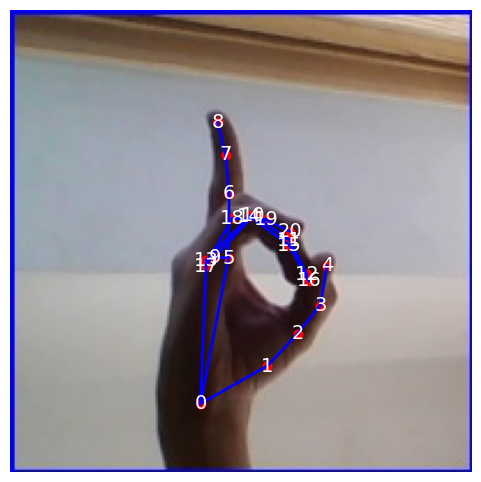

In [ ]:
def imprimir_landmarks(base_dir: str, letter: str, image_name: str):

    # 1. Construir y verificar la ruta
    image_path = os.path.join(base_dir, letter, image_name)

    if not os.path.exists(image_path):
        print(f"Error: No se encontró la imagen en la ruta: {image_path}")
        return

    # 2. Cargar imagen con OpenCV
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error: No se pudo cargar la imagen: {image_path}")
        return

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 3. Preparar imagen para MediaPipe y detectar
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=img_rgb)
    results = hand_landmarker.detect(mp_image)

    if not results.hand_landmarks:
        print(f"No se detectó ninguna mano en: {image_path}")
        return

    # 4. Extraer la primera mano detectada
    hand_landmarks = results.hand_landmarks[0]

    x = [lm.x for lm in hand_landmarks]
    y = [lm.y for lm in hand_landmarks]

    hand_connections = [
        (0, 1), (1, 2), (2, 3), (3, 4),                 # Pulgar
        (0, 5), (5, 6), (6, 7), (7, 8),                 # Índice
        (5, 9), (9, 10), (10, 11), (11, 12),            # Medio
        (9, 13), (13, 14), (14, 15), (15, 16),          # Anular
        (0, 17), (13, 17), (17, 18), (18, 19), (19, 20) # Meñique
    ]

    # 5. Ploteo de las coordenadas + landmarks
    plt.figure(figsize=(6,6))
    plt.imshow(img_rgb)
    plt.axis("off")

    for (i, j) in hand_connections:
        plt.plot(
            [x[i] * img_rgb.shape[1], x[j] * img_rgb.shape[1]],
            [y[i] * img_rgb.shape[0], y[j] * img_rgb.shape[0]],
            c="blue", linewidth=2
        )

    for i, (xi, yi) in enumerate(zip(x, y)):
        plt.scatter(xi * img_rgb.shape[1], yi * img_rgb.shape[0], c="red", s=40)
        plt.text(xi * img_rgb.shape[1], yi * img_rgb.shape[0], str(i),
                 fontsize=14, color="white", ha="center", va="center")

    plt.show()

# ===== CÓMO LLAMAR A LA FUNCIÓN (Ejemplo para probarla) =====
train_dir = os.path.join(path, "asl_alphabet_train/asl_alphabet_train")
#imprimir_landmarks(train_dir, "A", "A17.jpg")
#imprimir_landmarks(train_dir, "B", "B1.jpg")
#imprimir_landmarks(train_dir, "C", "C47.jpg")
imprimir_landmarks(train_dir, "D", "D67.jpg")
#imprimir_landmarks(train_dir, "E", "E107.jpg")

# Primera parte: Features

En este punto se espera que completen 5 features para la clasificación de cada letra.

In [ ]:
df_train[df_train['label'] == 'A'].head()

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x55,x56,x57,x58,x59,x60,x61,x62,label,filename
0,0.710994,0.526506,-6.379686e-08,0.790574,0.492812,-0.020414,0.853101,0.415440,-0.026126,0.874469,...,0.330430,-0.067353,0.692726,0.380670,-0.066640,0.691506,0.427087,-0.056181,A,A629.jpg
1,0.798952,0.778048,-1.357380e-07,0.890370,0.734538,-0.016895,0.949099,0.654878,-0.023302,0.952535,...,0.579777,-0.065345,0.763947,0.629646,-0.058398,0.768737,0.670747,-0.046405,A,A2344.jpg
2,0.304351,0.733157,-4.207596e-07,0.388243,0.662018,-0.027001,0.445055,0.566362,-0.036320,0.439179,...,0.533036,-0.064286,0.213410,0.590762,-0.057504,0.234677,0.632301,-0.042124,A,A1675.jpg
3,0.298500,0.737965,-4.056078e-07,0.385449,0.663847,-0.025585,0.444554,0.565071,-0.033985,0.443242,...,0.532047,-0.061051,0.213888,0.588788,-0.054867,0.235023,0.629717,-0.040518,A,A1672.jpg
4,0.478017,0.579524,-1.247552e-07,0.581673,0.516893,-0.024830,0.642843,0.396127,-0.034154,0.654335,...,0.347637,-0.105044,0.389851,0.410786,-0.094797,0.401610,0.462108,-0.076332,A,A378.jpg


In [ ]:
# Hagamos una feature para ver si el pulgar está extendido
# Para eso tomamos la landmark 4 (punta del pulgar) y vemos
# su distancia a la landmark 17 (pinky finger mcp)

def distancia_pulgar(data):
  # Vemos las landmarks necesarias
  thumb_tip = data[['x12', 'x13', 'x14']].values
  pinky_mcp = data[['x51', 'x52', 'x53']].values

  wrist   = data[['x0',  'x1',  'x2' ]].values
  mid_mcp = data[['x27', 'x28', 'x29']].values

  # Normalizamos con la distancia de la palma de la mano
  raw_dist = np.linalg.norm(thumb_tip - pinky_mcp, axis=1)
  escalamiento = np.linalg.norm(wrist - mid_mcp,  axis=1)

  return raw_dist / escalamiento

# Encontramos u umbral para separar letras (A,C,D) - (B, E)

df_train['ratio_pulgar'] = distancia_pulgar(df_train)

print(df_train.loc[df_train['label'] == 'A', 'ratio_pulgar'].mean()) #1.24776581
print(df_train.loc[df_train['label'] == 'B', 'ratio_pulgar'].mean()) #0.45198490
print(df_train.loc[df_train['label'] == 'C', 'ratio_pulgar'].mean()) #1.28252143
print(df_train.loc[df_train['label'] == 'D', 'ratio_pulgar'].mean()) #0.89323014
print(df_train.loc[df_train['label'] == 'E', 'ratio_pulgar'].mean()) #0.37158164

# Tomamos el umbral = 0.6

def pulgar_extendido(data, umbral=0.6):
  return data['ratio_pulgar'] > umbral

df_train['pulgar_extendido'] = pulgar_extendido(df_train)

df_train[df_train['label'] == 'C'].head() # A simple vista se ve bien

1.247770659330172
0.4519936726782923
1.282486561801691
0.8932290545859829
0.37158094680404197


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x57,x58,x59,x60,x61,x62,label,filename,ratio_pulgar,pulgar_extendido
1470,0.384491,0.667138,9.341776e-07,0.520935,0.696977,-0.017432,0.627222,0.670568,-0.020828,0.711824,...,0.662820,0.346920,-0.016069,0.715530,0.332134,-0.024109,C,C770.jpg,1.230374,True
1471,0.415505,0.750537,1.760074e-06,0.548018,0.777755,-0.065123,0.680103,0.727665,-0.107393,0.792163,...,0.711174,0.393195,-0.091219,0.787764,0.398593,-0.089567,C,C2829.jpg,1.530869,True
1472,0.130377,0.913853,-6.387328e-07,0.195001,0.819019,-0.063870,0.297118,0.727882,-0.115075,0.383217,...,0.163998,0.958749,-0.207722,0.154552,0.948261,-0.203170,C,C1468.jpg,2.259549,True
1473,0.244470,0.371953,1.227222e-06,0.381078,0.379715,0.002794,0.486831,0.337182,-0.013786,0.577594,...,0.585553,0.143489,-0.113335,0.646768,0.169243,-0.111819,C,C1213.jpg,1.276328,True
1474,0.186254,0.768599,1.010559e-06,0.332266,0.773754,-0.048021,0.442460,0.727453,-0.068062,0.525058,...,0.360621,0.354260,-0.056231,0.413635,0.327994,-0.070428,C,C301.jpg,1.296140,True


In [ ]:
# La segunda feature será si el dedo del medio está extendido
# Para eso tomamos la landmark 12 (punta del medio) y vemos
# su distancia a la landmark 0 (muñeca)

def distancia_medio(data):
  # Vemos las landmarks necesarias
  mid_tip = data[['x36', 'x37', 'x38']].values
  wrist   = data[['x0',  'x1',  'x2' ]].values
  mid_mcp = data[['x27', 'x28', 'x29']].values

  # Normalizamos con la distancia de la palma de la mano
  raw_dist = np.linalg.norm(mid_tip - wrist, axis=1)
  escalamiento = np.linalg.norm(wrist - mid_mcp,  axis=1)

  return raw_dist / escalamiento

# Encontramos un umbral para separar letras (A,D,E) - (B, C)

df_train['ratio_medio'] = distancia_medio(df_train)

print(df_train.loc[df_train['label'] == 'A', 'ratio_medio'].mean()) #0.795381198
print(df_train.loc[df_train['label'] == 'B', 'ratio_medio'].mean()) #1.908467657
print(df_train.loc[df_train['label'] == 'C', 'ratio_medio'].mean()) #1.935059989
print(df_train.loc[df_train['label'] == 'D', 'ratio_medio'].mean()) #1.404825527
print(df_train.loc[df_train['label'] == 'E', 'ratio_medio'].mean()) #1.000203896

# Tomamos el umbral = 1.7

def medio_extendido(data, umbral=1.7):
  return data['ratio_medio'] > umbral

df_train['medio_extendido'] = medio_extendido(df_train)

df_train[df_train['label'] == 'A'].head() # A simple vista se ve bien

0.7953833254194488
1.908471546695132
1.9350437647310086
1.4048106684336905
1.0002041046133412


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x59,x60,x61,x62,label,filename,ratio_pulgar,pulgar_extendido,ratio_medio,medio_extendido
0,0.710994,0.526506,-6.379686e-08,0.790574,0.492812,-0.020414,0.853101,0.415440,-0.026126,0.874469,...,-0.066640,0.691506,0.427087,-0.056181,A,A629.jpg,1.256366,True,0.868429,False
1,0.798952,0.778048,-1.357380e-07,0.890370,0.734538,-0.016895,0.949099,0.654878,-0.023302,0.952535,...,-0.058398,0.768737,0.670747,-0.046405,A,A2344.jpg,1.144808,True,0.755915,False
2,0.304351,0.733157,-4.207596e-07,0.388243,0.662018,-0.027001,0.445055,0.566362,-0.036320,0.439179,...,-0.057504,0.234677,0.632301,-0.042124,A,A1675.jpg,1.261813,True,0.728233,False
3,0.298500,0.737965,-4.056078e-07,0.385449,0.663847,-0.025585,0.444554,0.565071,-0.033985,0.443242,...,-0.054867,0.235023,0.629717,-0.040518,A,A1672.jpg,1.204546,True,0.720884,False
4,0.478017,0.579524,-1.247552e-07,0.581673,0.516893,-0.024830,0.642843,0.396127,-0.034154,0.654335,...,-0.094797,0.401610,0.462108,-0.076332,A,A378.jpg,1.326096,True,0.764297,False


In [ ]:
# La tercera feature será si el dedo indice está extendido
# Para eso tomamos la landmark 8 (punta del índice) y vemos
# su distancia a la landmark 0 (muñeca)

def distancia_indice(data):
  # Vemos las landmarks necesarias
  index_tip = data[['x24', 'x25', 'x26']].values
  wrist   = data[['x0',  'x1',  'x2' ]].values
  mid_mcp = data[['x27', 'x28', 'x29']].values

  # Normalizamos con la distancia de la palma de la mano
  raw_dist = np.linalg.norm(index_tip - wrist, axis=1)
  escalamiento = np.linalg.norm(wrist - mid_mcp,  axis=1)

  return raw_dist / escalamiento

# Encontramos un umbral para separar letras (B,C,D) - (A, E)

df_train['ratio_indice'] = distancia_indice(df_train)

print(df_train.loc[df_train['label'] == 'A', 'ratio_indice'].mean()) #1.05540430
print(df_train.loc[df_train['label'] == 'B', 'ratio_indice'].mean()) #1.81315389
print(df_train.loc[df_train['label'] == 'C', 'ratio_indice'].mean()) #1.87915961
print(df_train.loc[df_train['label'] == 'D', 'ratio_indice'].mean()) #1.80994828
print(df_train.loc[df_train['label'] == 'E', 'ratio_indice'].mean()) #1.07833926

# Tomamos el umbral = 1.4

def indice_extendido(data, umbral=1.4):
  return data['ratio_indice'] > umbral

df_train['indice_extendido'] = indice_extendido(df_train)

df_train[df_train['label'] == 'B'].head() # A simple vista se ve bien


1.0554050753959496
1.813158490678562
1.8791555615854139
1.8099493963287285
1.078339849989664


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x61,x62,label,filename,ratio_pulgar,pulgar_extendido,ratio_medio,medio_extendido,ratio_indice,indice_extendido
722,0.376348,0.895007,1.127188e-07,0.503387,0.858362,-0.036671,0.588728,0.747348,-0.043918,0.538906,...,0.349376,-0.106086,B,B1038.jpg,0.291175,False,1.895050,True,1.791509,True
723,0.524275,0.831540,-3.186314e-07,0.516816,0.736473,-0.023269,0.573539,0.617523,-0.032897,0.632738,...,0.382105,-0.130689,B,B2856.jpg,0.233401,False,1.952193,True,1.839475,True
724,0.437660,0.696218,6.002743e-07,0.519550,0.644952,-0.047313,0.567502,0.556374,-0.068846,0.505807,...,0.213021,-0.090230,B,B2011.jpg,0.189320,False,1.940491,True,1.851342,True
725,0.443657,0.819817,2.444455e-07,0.558788,0.777142,-0.033680,0.634433,0.687243,-0.043413,0.587339,...,0.342190,-0.079137,B,B1173.jpg,0.259777,False,1.871372,True,1.788364,True
726,0.737402,0.680610,2.441804e-07,0.829849,0.636434,-0.026351,0.898938,0.559317,-0.032294,0.878770,...,0.270508,-0.061367,B,B358.jpg,0.435369,False,1.893222,True,1.799060,True


In [ ]:
# La cuarta feature será si el dedo anular está extendido
# Para eso tomamos la landmark 16 (punta del anular) y vemos
# su distancia a la landmark 13 (anular  mcp)

def distancia_anular(data):
  # Vemos las landmarks necesarias
  anular_tip = data[['x48', 'x49', 'x50']].values
  anular_mcp = data[['x39', 'x40', 'x41']].values
  wrist   = data[['x0',  'x1',  'x2' ]].values
  mid_mcp = data[['x27', 'x28', 'x29']].values

  # Normalizamos con la distancia de la palma de la mano
  raw_dist = np.linalg.norm(anular_tip - anular_mcp, axis=1)
  escalamiento = np.linalg.norm(wrist - mid_mcp,  axis=1)

  return raw_dist / escalamiento

# Encontramos un umbral para separar letras (B,C,D) - (A, E)

df_train['ratio_anular'] = distancia_anular(df_train)

print(df_train.loc[df_train['label'] == 'A', 'ratio_anular'].mean()) #0.44160546
print(df_train.loc[df_train['label'] == 'B', 'ratio_anular'].mean()) #0.87973549
print(df_train.loc[df_train['label'] == 'C', 'ratio_anular'].mean()) #1.03953557
print(df_train.loc[df_train['label'] == 'D', 'ratio_anular'].mean()) #0.78855518
print(df_train.loc[df_train['label'] == 'E', 'ratio_anular'].mean()) #0.17630401

# Tomamos el umbral = 0.5

def anular_extendido(data, umbral=0.5):
  return data['ratio_anular'] > umbral

df_train['anular_extendido'] = anular_extendido(df_train)

df_train[df_train['label'] == 'B'].head() # A simple vista se ve bien


0.44160546930478184
0.8797354983685732
1.039535571639126
0.7885551838110317
0.17630401916231


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,label,filename,ratio_pulgar,pulgar_extendido,ratio_medio,medio_extendido,ratio_indice,indice_extendido,ratio_anular,anular_extendido
722,0.376348,0.895007,1.127188e-07,0.503387,0.858362,-0.036671,0.588728,0.747348,-0.043918,0.538906,...,B,B1038.jpg,0.291175,False,1.895050,True,1.791509,True,0.867334,True
723,0.524275,0.831540,-3.186314e-07,0.516816,0.736473,-0.023269,0.573539,0.617523,-0.032897,0.632738,...,B,B2856.jpg,0.233401,False,1.952193,True,1.839475,True,1.072229,True
724,0.437660,0.696218,6.002743e-07,0.519550,0.644952,-0.047313,0.567502,0.556374,-0.068846,0.505807,...,B,B2011.jpg,0.189320,False,1.940491,True,1.851342,True,0.881886,True
725,0.443657,0.819817,2.444455e-07,0.558788,0.777142,-0.033680,0.634433,0.687243,-0.043413,0.587339,...,B,B1173.jpg,0.259777,False,1.871372,True,1.788364,True,0.865050,True
726,0.737402,0.680610,2.441804e-07,0.829849,0.636434,-0.026351,0.898938,0.559317,-0.032294,0.878770,...,B,B358.jpg,0.435369,False,1.893222,True,1.799060,True,0.864044,True


In [ ]:
# La última feature será el "esparcimiento" de los dedos
# Para eso tomamos la landmark 8 (punta del indice) y vemos
# su distancia a la landmark 20 (punta del meñique)

def esparcimiento(data):
  # Vemos las landmarks necesarias
  index_tip = data[['x24', 'x25', 'x26']].values
  pinky_tip = data[['x60', 'x61', 'x62']].values
  wrist   = data[['x0',  'x1',  'x2' ]].values
  mid_mcp = data[['x27', 'x28', 'x29']].values

  # Normalizamos con la distancia de la palma de la mano
  raw_dist = np.linalg.norm(index_tip - pinky_tip, axis=1)
  escalamiento = np.linalg.norm(wrist - mid_mcp,  axis=1)

  return raw_dist / escalamiento

# Encontramos un umbral para separar letras (B,C,E) - (A, D)

df_train['esparcimiento'] = esparcimiento(df_train)

print(df_train.loc[df_train['label'] == 'A', 'esparcimiento'].mean()) #0.7723399
print(df_train.loc[df_train['label'] == 'B', 'esparcimiento'].mean()) #0.5815966
print(df_train.loc[df_train['label'] == 'C', 'esparcimiento'].mean()) #0.5386273
print(df_train.loc[df_train['label'] == 'D', 'esparcimiento'].mean()) #0.8641852
print(df_train.loc[df_train['label'] == 'E', 'esparcimiento'].mean()) #0.6264299

# Tomamos el umbral = 0.6

def esparcido(data, umbral=0.6):
  return data['esparcimiento'] > umbral

df_train['esparcido'] = esparcido(df_train)

df_train[df_train['label'] == 'B'].head() # A simple vista se ve bien


0.7723428257334479
0.5815994707607937
0.538584671011303
0.8641726112676725
0.6264306699986303


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,ratio_pulgar,pulgar_extendido,ratio_medio,medio_extendido,ratio_indice,indice_extendido,ratio_anular,anular_extendido,esparcimiento,esparcido
722,0.376348,0.895007,1.127188e-07,0.503387,0.858362,-0.036671,0.588728,0.747348,-0.043918,0.538906,...,0.291175,False,1.895050,True,1.791509,True,0.867334,True,0.523378,False
723,0.524275,0.831540,-3.186314e-07,0.516816,0.736473,-0.023269,0.573539,0.617523,-0.032897,0.632738,...,0.233401,False,1.952193,True,1.839475,True,1.072229,True,0.642208,True
724,0.437660,0.696218,6.002743e-07,0.519550,0.644952,-0.047313,0.567502,0.556374,-0.068846,0.505807,...,0.189320,False,1.940491,True,1.851342,True,0.881886,True,0.640799,True
725,0.443657,0.819817,2.444455e-07,0.558788,0.777142,-0.033680,0.634433,0.687243,-0.043413,0.587339,...,0.259777,False,1.871372,True,1.788364,True,0.865050,True,0.534481,False
726,0.737402,0.680610,2.441804e-07,0.829849,0.636434,-0.026351,0.898938,0.559317,-0.032294,0.878770,...,0.435369,False,1.893222,True,1.799060,True,0.864044,True,0.589624,False


Nos quedamos con nuestras features para entrenar al modelo de active learning.

In [ ]:
df = df_train[['label', 'filename','pulgar_extendido','medio_extendido', 'indice_extendido', 'esparcido', 'anular_extendido']]
df.head()

,label,filename,pulgar_extendido,medio_extendido,indice_extendido,esparcido,anular_extendido
0,A,A629.jpg,True,False,False,True,False
1,A,A2344.jpg,True,False,False,True,False
2,A,A1675.jpg,True,False,False,True,False
3,A,A1672.jpg,True,False,False,True,False
4,A,A378.jpg,True,False,False,True,False


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

features = ['pulgar_extendido','medio_extendido', 'indice_extendido', 'esparcido', 'anular_extendido']

X = df[features].values
y = df['label'].values

train, temp = train_test_split(df, test_size=0.2, random_state=42, stratify=y)
val, test = train_test_split(temp, test_size=0.5, random_state=42, stratify=temp['label'])

X_train = train[features]
y_train = train['label']

X_val = val[features]
y_val = val['label']

X_test = test[features]
y_test = test['label']

scaler = StandardScaler().set_output(transform="pandas")
X_train_sc = scaler.fit_transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)

Referencia: Lorca. R. (2026). Tarea 2, Archivo DCCoches. Creación propia.

# Segunda Parte: Active Learning (Simulación Manual)

En esta sección, ustedes tomarán el rol del "Oráculo" (humano experto). Entrenaremos modelos usando muy pocos datos iniciales y dejaremos que el algoritmo decida qué nuevas imágenes necesita que ustedes etiqueten.

Tu tarea:

1. Definir los 3 clasificadores base (Decision Tree, Random Forest, SVM).

2. Configurar las 4 estrategias de muestreo (2 UncertaintySampling, 1 RandomSampling y 1 QueryByCommittee).

3. Completar la función run_manual_active_learning.

**Implementamos las 4 estrategias de muestreo:**
1. random_sampling : Etiquetas al azar del pool sin etiquetar
2. entropy sampling : Selecciona el ejemplo con mayor entropía
3. margin sampling : Considera las clases más probables y selecciona el ejemplo con menor margen.
4. query by comitee : Idea más compleja y representativa, se tiene un comité de modelos en donde se le pasa un sample sin label (query) y cada modelo da su predicción. Se elige las muestras con más desacuerdo.

Referencias:
- Material de clases

- "Modal. (s. f.). Uncertainty sampling. https://modal-python.readthedocs.io/en/latest/content/query_strategies/uncertainty_sampling.html"

- ModAL. (s. f.). Query by committee. https://modal-python.readthedocs.io/en/latest/content/examples/query_by_committee.html

In [ ]:
from skactiveml.classifier import SklearnClassifier
from skactiveml.pool import RandomSampling, UncertaintySampling, QueryByCommittee
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.base import clone

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

modelos = [
    {
        "modelo": "Decision Tree",
        "instance": SklearnClassifier(DecisionTreeClassifier(random_state=42),
                                      classes=np.array([0, 1, 2, 3, 4]))
    },
    {
        "modelo": "Random Forest",
        "instance": SklearnClassifier(RandomForestClassifier(n_estimators=100,
                                                             random_state=42),
                                      classes=np.array([0, 1, 2, 3, 4]))
    },
    {
        "modelo": "SVM",
        "instance": SklearnClassifier(SVC(probability=True, random_state=42),
                                      classes=np.array([0, 1, 2, 3, 4]))
    }
]

estrategias = {
    "RandomSampling": RandomSampling(random_state=42),
    "Entropy":        UncertaintySampling(method='entropy'),
    "Margin":         UncertaintySampling(method='margin_sampling'),
    "QBC":            QueryByCommittee()
}

Referencia:

Arévalo F, Samsó J. (20 de abril 2026). *Ayudantía 2: Active Learning*. Archivo .ipynb. Recuperado de Canvas uc.

Funciones Auxiliares que deben utilizar. No modificar.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

def registrar_metricas_viewer(viewer, iteration, y_active_pool, missing_label, y_test, y_pred, class_names):
    """
    Calcula las métricas de desempeño actuales y actualiza los gráficos de la interfaz Viewer.
    """
    labeled_values = y_active_pool[y_active_pool != missing_label]
    class_counts_new = {
        cls: int(np.sum(labeled_values == idx_cls))
        for idx_cls, cls in enumerate(class_names)
    }

    accuracy = accuracy_score(y_test, y_pred)
    precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)

    viewer.agregar_historial(
        iteration=iteration,
        etiquetadas=int(np.sum(y_active_pool != missing_label)),
        accuracy=accuracy,
        precision_macro=precision_macro,
        recall_macro=recall_macro,
        class_counts=class_counts_new
    )
    print(f"Iteración {iteration} registrada. Accuracy: {accuracy:.4f}")

def interactuar_con_oraculo(viewer, query_idx, class_names, filenames_pool, y_active_pool, class_to_encoded, iteration):
    """
    Despliega la interfaz para que el usuario (Oráculo) etiquete las imágenes seleccionadas.
    Actualiza y retorna el arreglo y_active_pool con las nuevas etiquetas.
    """
    respuestas = viewer.solicitar_etiquetado(query_idx, class_names=class_names, filenames=filenames_pool, iteration=iteration)
    for idx, cls_name in respuestas.items():
        y_active_pool[idx] = class_to_encoded[cls_name]
    return y_active_pool

In [ ]:
import importlib
import al_interactive_workflow
importlib.reload(al_interactive_workflow)
from al_interactive_workflow import Viewer

# Uso de IA [1]

def run_manual_active_learning(estimator, X, y_true, filenames, viewer, query_selector, strategy_name,
                               initial_size=5, query_size=5, test_size=0.2, random_state=42, max_iterations=10):
  # 1. Preparamos el escenario
  X = np.array(X)
  # Transformamos las labels a numeros A->0, B->1 ...
  clases = sorted(np.unique(y_true).tolist())
  class_to_encoded = {cls: idx for idx, cls in enumerate(clases)}
  y_temp = []
  for etiqueta in y_true:
    codigo = class_to_encoded[etiqueta]
    y_temp.append(codigo)

  y_encoded = np.array(y_temp)
  missing_label = -1 # Nuestro equivalente a NaN

  # Spliteamos el pool / test
  (X_pool_full, X_test, y_pool_full, y_test, filenames_pool_full, _) = train_test_split(
      X, y_encoded, filenames, test_size=test_size,
      random_state=random_state, stratify=y_encoded
    )

  # Todo parte sin etiquetar
  y_active_pool = np.full(len(y_pool_full), missing_label)

  # 2. ARRANQUE EN FRÍO (Cold Start)
  rng = np.random.default_rng(random_state)
  per_class = max(1, initial_size // len(clases))
  for cls_idx in range(len(clases)):
      class_idx = np.where(y_pool_full == cls_idx)[0]
      elegido = rng.choice(class_idx, size=per_class, replace=False)
      y_active_pool[elegido] = y_pool_full[elegido]

  # Entrenamiento inicial para que la estrategia pueda consultar en iteración 1
  idx_init = np.where(y_active_pool != missing_label)[0]
  estimator.fit(X_pool_full[idx_init], y_active_pool[idx_init])

  # 3. EL CICLO DE ACTIVE LEARNING
  for iteration in range(1, max_iterations + 1):
      idx_etiquetados = np.where(y_active_pool != missing_label)[0]
      idx_noetiquetados = np.where(y_active_pool == missing_label)[0]

      if len(idx_noetiquetados) == 0:
           print("No quedan más datos que etiquetar (pool vacío).")
           break

      # Entrenar con lo etiquetado hasta ahora
      X_etiquetados = X_pool_full[idx_etiquetados]
      y_etiquetados  = y_active_pool[idx_etiquetados]
      estimator.fit(X_etiquetados, y_etiquetados)

      # Selección (Query strategy)
      y_active_pool_nan = y_active_pool.astype(float)
      y_active_pool_nan[y_active_pool_nan == missing_label] = np.nan

      if strategy_name == "QBC":
        # Paso extra enunciado: Creamos con bagging el comité
        # Extraemos el modelo sklearn base del SklearnClassifier
        modelo_base = clone(estimator.estimator)

        # Creamos el comité como lista de SklearnClassifiers
        # skactiveml acepta una lista de clasificadores como ensemble
        n_members = 10
        comite = []
        rng_boot = np.random.default_rng(random_state)

        idx_etiquetados_qbc = np.where(y_active_pool != missing_label)[0]
        X_boot = X_pool_full[idx_etiquetados_qbc]
        y_boot_nan = y_active_pool_nan[idx_etiquetados_qbc]

        for _ in range(n_members):
            idx = rng_boot.choice(len(X_boot), size=len(X_boot), replace=True)
            miembro = SklearnClassifier(clone(modelo_base), classes=np.array([0,1,2,3,4]))
            miembro.fit(X_boot[idx], y_boot_nan[idx])
            comite.append(miembro)

        query_idx = query_selector.query(
            X=X_pool_full, y=y_active_pool_nan,
            ensemble=comite,  # lista de clasificadores
            batch_size=query_size
        )
      elif strategy_name == "RandomSampling":
          query_idx = query_selector.query(
              X=X_pool_full, y=y_active_pool_nan,
              batch_size=query_size
          )
      else:  # Entropy y Margin
          query_idx = query_selector.query(
              X=X_pool_full, y=y_active_pool_nan,
              clf=estimator, batch_size=query_size
          )

      # Oráculo
      y_active_pool = interactuar_con_oraculo(
          viewer, query_idx, clases, filenames_pool_full, y_active_pool,
          class_to_encoded, iteration
      )

      # Actualizacion y re-entrenamiento
      idx_etiquetados = np.where(y_active_pool != missing_label)[0]
      X_etiquetados = X_pool_full[idx_etiquetados]
      y_etiquetados = y_active_pool[idx_etiquetados]
      estimator.fit(X_etiquetados, y_etiquetados)

      # Predecir en test para calcular métricas
      y_pred = estimator.predict(X_test)

      # Registrar métricas en el Viewer
      registrar_metricas_viewer(
           viewer, iteration, y_active_pool,
          missing_label, y_test, y_pred, clases
      )

Este código ejecuta la interfaz que utilizarán, toma los modelos y estrategias previamente definidos y llama a la función run_manual_active_learning. Modifiquen el llamado a la función en las partes comentadas.


Selecciona el modelo para Active Learning manual:
  1. Decision Tree
  2. Random Forest
  3. SVM
Elige una opcion (numero o texto exacto): 3

Selecciona la estrategia de muestreo:
  1. RandomSampling
  2. Entropy
  3. Margin
  4. QBC
Elige una opcion (numero o texto exacto): 4


evento,iteracion,idx_pool,filename,image_path,imagen_mostrada,label_elegida
registrado,1,741,C1984.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/C/C1984.jpg,True,C
registrado,1,636,D626.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/D/D626.jpg,True,D
registrado,1,1697,D148.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/D/D148.jpg,True,D
registrado,1,1309,D1613.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/D/D1613.jpg,True,D
registrado,1,1564,D2095.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/D/D2095.jpg,True,D
registrado,2,834,D978.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/D/D978.jpg,True,D
registrado,2,208,B464.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/B/B464.jpg,True,B
registrado,2,157,B833.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/B/B833.jpg,True,B
registrado,2,1264,B1986.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/B/B1986.jpg,True,B
registrado,2,1632,B2496.jpg,/kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train/B/B2496.jpg,True,B



Etiqueta para idx=741, archivo=C1984.jpg (opciones: A, B, C, D, E): 
>>> C



Etiqueta para idx=636, archivo=D626.jpg (opciones: A, B, C, D, E): 
>>> D



Etiqueta para idx=1697, archivo=D148.jpg (opciones: A, B, C, D, E): 
>>> D



Etiqueta para idx=1309, archivo=D1613.jpg (opciones: A, B, C, D, E): 
>>> D



Etiqueta para idx=1564, archivo=D2095.jpg (opciones: A, B, C, D, E): 
>>> D
Iteracion 1 | etiquetadas=10 | acc=0.4983 | precision=0.6491 | recall=0.4767


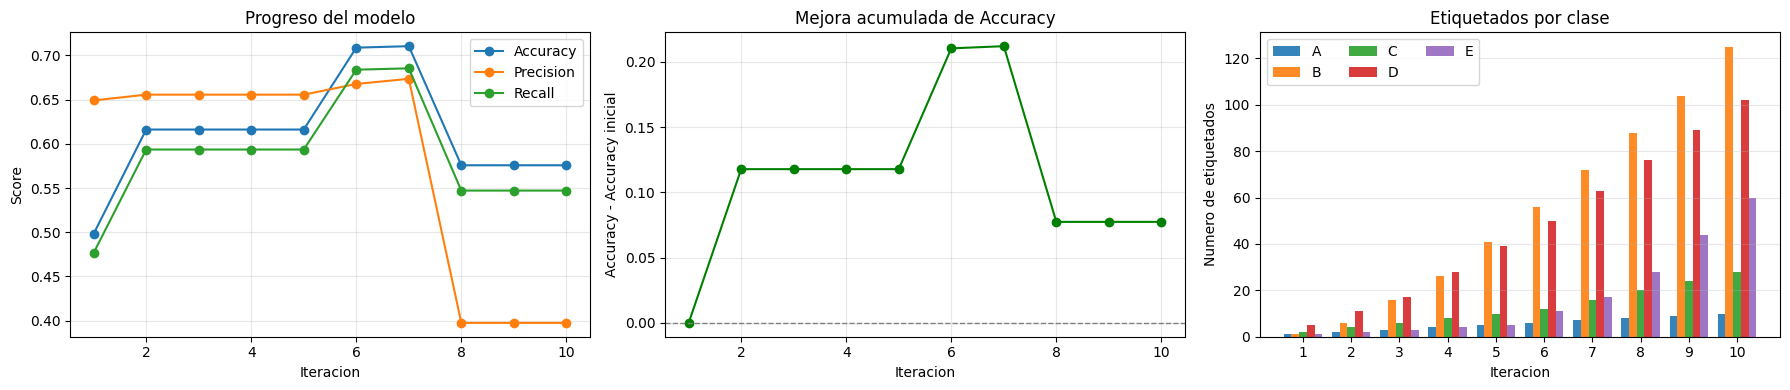

iteracion,etiquetadas,accuracy,precision_macro,recall_macro,label_count_A,label_count_B,label_count_C,label_count_D,label_count_E
1,10,0.498316,0.649077,0.476743,1,1,2,5,1
2,15,0.616162,0.655610,0.593561,2,6,4,11,2
3,20,0.616162,0.655610,0.593561,3,16,6,17,3
4,25,0.616162,0.655610,0.593561,4,26,8,28,4
5,30,0.616162,0.655610,0.593561,5,41,10,39,5
6,35,0.708754,0.667688,0.683849,6,56,12,50,11
7,40,0.710438,0.673525,0.685364,7,72,16,63,17
8,45,0.575758,0.397528,0.547134,8,88,20,76,28
9,50,0.575758,0.397528,0.547134,9,104,24,89,44
10,55,0.575758,0.397528,0.547134,10,125,28,102,60


Iteración 1 registrada. Accuracy: 0.4983



Etiqueta para idx=834, archivo=D978.jpg (opciones: A, B, C, D, E): 
>>> D



Etiqueta para idx=208, archivo=B464.jpg (opciones: A, B, C, D, E): 
>>> B



Etiqueta para idx=157, archivo=B833.jpg (opciones: A, B, C, D, E): 
>>> B


...


Etiqueta para idx=1549, archivo=B1531.jpg (opciones: A, B, C, D, E): 
>>> B



Etiqueta para idx=1831, archivo=B1128.jpg (opciones: A, B, C, D, E): 
>>> B



Etiqueta para idx=417, archivo=B1165.jpg (opciones: A, B, C, D, E): 
>>> B



Etiqueta para idx=299, archivo=B1851.jpg (opciones: A, B, C, D, E): 
>>> B



Etiqueta para idx=63, archivo=B1529.jpg (opciones: A, B, C, D, E): 
>>> B
Iteracion 10 | etiquetadas=55 | acc=0.5758 | precision=0.3975 | recall=0.5471
Iteración 10 registrada. Accuracy: 0.5758


In [ ]:
filenames_series = train["filename"].values
image_base_dir = train_dir
image_index = Viewer._build_image_index(image_base_dir)

viewer = Viewer(
    image_base_dir=image_base_dir,
    image_index=image_index,
)

model_names = [cfg["modelo"] for cfg in modelos]
selected_model_name = Viewer._ask_choice("Selecciona el modelo para Active Learning manual:", model_names)
selected_model_cfg = next(cfg for cfg in modelos if cfg["modelo"] == selected_model_name)

strategy_names = list(estrategias.keys())
selected_strategy_name = Viewer._ask_choice("Selecciona la estrategia de muestreo:", strategy_names)
query_selector_to_use = estrategias[selected_strategy_name]


run_manual_active_learning(
    estimator=selected_model_cfg["instance"],
    X=X_train_sc, # Ajustado
    y_true=y_train.values, # Ajustado
    filenames =np.asarray(filenames_series),
    viewer=viewer,
    query_selector=query_selector_to_use,
    strategy_name=selected_strategy_name,
    initial_size=5,
    query_size=5,
    test_size=0.2,
    random_state=42,
    max_iterations=10,
)

## Tercera Parte: Simulación Automatizada de Active Learning

En esta etapa se espera que automaticen el rol del "Oráculo" usando las etiquetas reales del dataset. Esto nos permitirá simular y evaluar cómo se comportan nuestros 3 modelos combinados con diferentes estrategias de muestreo a mayor escala pero con un presupuesto máximo de 150 Tokens (1 token = 1 nueva imagen etiquetada por el oráculo).